In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from lime.lime_tabular import LimeTabularExplainer

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report

In [2]:
df = pd.read_csv("heart.csv")

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Columns:", df.columns.tolist())

display(df.head())

Dataset Shape: (303, 14)
Missing Values: 0
Duplicate Rows: 1
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
X = df.drop(columns=["target"])
y = df["target"]

feature_names = X.columns.tolist()

categorical_columns = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

categorical_features = [
    X.columns.get_loc(col)
    for col in categorical_columns
]

categorical_names = {
    X.columns.get_loc(col): [
        str(v) for v in sorted(X[col].dropna().unique())
    ]
    for col in categorical_columns
}

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))
print("Total Features:", len(feature_names))

Training Rows: 242
Testing Rows: 61
Total Features: 13


In [4]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print(classification_report(y_test, y_pred))

Model Accuracy: 81.97 %
              precision    recall  f1-score   support

           0       0.95      0.64      0.77        28
           1       0.76      0.97      0.85        33

    accuracy                           0.82        61
   macro avg       0.85      0.81      0.81        61
weighted avg       0.85      0.82      0.81        61



In [5]:
rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "RF Importance": model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    "RF Importance",
    ascending=False
)

rf_importance["RF Rank"] = range(
    1, len(rf_importance) + 1
)

display(rf_importance.round(4))

,Feature,RF Importance,RF Rank
2,cp,0.1536,1
12,thal,0.1194,2
7,thalach,0.1130,3
9,oldpeak,0.1108,4
11,ca,0.0869,5
4,chol,0.0849,6
0,age,0.0800,7
3,trestbps,0.0736,8
8,exang,0.0630,9
10,slope,0.0541,10


In [6]:
perm_result = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="accuracy",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": feature_names,
    "Permutation Importance": perm_result.importances_mean,
    "Importance Std": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    "Permutation Importance",
    ascending=False
)

permutation_df["Permutation Rank"] = range(
    1, len(permutation_df) + 1
)

display(permutation_df.round(4))

,Feature,Permutation Importance,Importance Std,Permutation Rank
11,ca,0.0762,0.0349,1
9,oldpeak,0.0246,0.0229,2
2,cp,0.0246,0.0354,3
8,exang,0.0230,0.0234,4
1,sex,0.0180,0.0102,5
12,thal,0.0098,0.0321,6
7,thalach,0.0082,0.0251,7
3,trestbps,0.0025,0.0119,8
10,slope,0.0000,0.0000,9
5,fbs,-0.0033,0.0066,10


In [7]:
shap_explainer = shap.TreeExplainer(model)

shap_explanation = shap_explainer(X_test)

shap_values_all = shap_explanation.values

if shap_values_all.ndim == 3:
    class_index = list(model.classes_).index(1)

    if shap_values_all.shape[1] == len(feature_names):
        shap_class_values = shap_values_all[:, :, class_index]
    else:
        shap_class_values = shap_values_all[:, class_index, :]
else:
    shap_class_values = shap_values_all

global_shap_importance = np.abs(
    shap_class_values
).mean(axis=0)

shap_global_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": global_shap_importance
})

shap_global_df = shap_global_df.sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

shap_global_df["SHAP Rank"] = range(
    1, len(shap_global_df) + 1
)

display(shap_global_df.round(4))

,Feature,Mean Absolute SHAP,SHAP Rank
2,cp,0.1082,1
12,thal,0.0939,2
11,ca,0.0759,3
9,oldpeak,0.0557,4
7,thalach,0.0528,5
8,exang,0.0497,6
10,slope,0.0429,7
1,sex,0.0302,8
4,chol,0.0288,9
0,age,0.0244,10


In [8]:
def predict_proba_lime(data):
    data = pd.DataFrame(
        data,
        columns=feature_names
    )
    return model.predict_proba(data)


lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=feature_names,
    class_names=[str(c) for c in model.classes_],
    categorical_features=categorical_features,
    categorical_names=categorical_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

sample = X_test.iloc[[0]]

predicted_class = model.predict(sample)[0]

lime_explanation = lime_explainer.explain_instance(
    data_row=sample.iloc[0].to_numpy(),
    predict_fn=predict_proba_lime,
    labels=[int(predicted_class)],
    num_features=len(feature_names),
    num_samples=3000
)

lime_map = dict(
    lime_explanation.as_map()[int(predicted_class)]
)

lime_contributions = np.array([
    lime_map.get(i, 0.0)
    for i in range(len(feature_names))
])

lime_local_df = pd.DataFrame({
    "Feature": feature_names,
    "LIME Contribution": lime_contributions,
    "LIME Importance": np.abs(lime_contributions)
})

lime_local_df = lime_local_df.sort_values(
    "LIME Importance",
    ascending=False
)

lime_local_df["LIME Rank"] = range(
    1, len(lime_local_df) + 1
)

print("Selected Test Observation")
display(sample)

print("Predicted Class:", predicted_class)

display(lime_local_df.round(4))

Selected Test Observation


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
179,57,1,0,150,276,0,0,112,1,0.6,1,1,1


Predicted Class: 0


,Feature,LIME Contribution,LIME Importance,LIME Rank
2,cp,0.1842,0.1842,1
11,ca,0.0943,0.0943,2
8,exang,0.0880,0.0880,3
7,thalach,0.0859,0.0859,4
1,sex,0.0708,0.0708,5
9,oldpeak,-0.0639,0.0639,6
4,chol,0.0595,0.0595,7
10,slope,0.0584,0.0584,8
12,thal,-0.0395,0.0395,9
3,trestbps,0.0388,0.0388,10


In [9]:
global_comparison = (
    rf_importance[["Feature", "RF Importance"]]
    .merge(
        permutation_df[["Feature", "Permutation Importance"]],
        on="Feature"
    )
    .merge(
        shap_global_df[["Feature", "Mean Absolute SHAP"]],
        on="Feature"
    )
)

score_columns = [
    "RF Importance",
    "Permutation Importance",
    "Mean Absolute SHAP"
]

for col in score_columns:
    values = global_comparison[col].clip(lower=0)
    maximum = values.max()

    global_comparison[col + " Normalized"] = (
        values / maximum if maximum > 0 else 0
    )

normalized_columns = [
    col + " Normalized" for col in score_columns
]

global_comparison["Manual Combined Score"] = (
    global_comparison[normalized_columns].mean(axis=1)
)

global_comparison["Average Rank"] = global_comparison[
    score_columns
].rank(ascending=False).mean(axis=1)

global_comparison = global_comparison.sort_values(
    "Manual Combined Score",
    ascending=False
)

global_comparison["Final Global Rank"] = range(
    1, len(global_comparison) + 1
)

display(global_comparison.round(4))

,Feature,RF Importance,Permutation Importance,Mean Absolute SHAP,RF Importance Normalized,Permutation Importance Normalized,Mean Absolute SHAP Normalized,Manual Combined Score,Average Rank,Final Global Rank
0,cp,0.1536,0.0246,0.1082,1.0000,0.3226,1.0000,0.7742,1.6667,1
4,ca,0.0869,0.0762,0.0759,0.5655,1.0000,0.7011,0.7555,3.0000,2
1,thal,0.1194,0.0098,0.0939,0.7771,0.1290,0.8676,0.5912,3.3333,3
3,oldpeak,0.1108,0.0246,0.0557,0.7215,0.3226,0.5146,0.5195,3.3333,4
2,thalach,0.1130,0.0082,0.0528,0.7358,0.1075,0.4879,0.4437,5.0000,5
8,exang,0.0630,0.0230,0.0497,0.4101,0.3011,0.4593,0.3901,6.3333,6
5,chol,0.0849,-0.0213,0.0288,0.5525,0.0000,0.2664,0.2730,9.3333,7
9,slope,0.0541,0.0000,0.0429,0.3524,0.0000,0.3966,0.2497,8.6667,8
6,age,0.0800,-0.0066,0.0244,0.5211,0.0000,0.2252,0.2487,9.3333,9
10,sex,0.0285,0.0180,0.0302,0.1852,0.2366,0.2787,0.2335,8.0000,10


In [10]:
sample_position = X_test.index.get_loc(sample.index[0])

local_shap_values = shap_class_values[sample_position]

local_comparison = pd.DataFrame({
    "Feature": feature_names,
    "Local SHAP Value": local_shap_values,
    "Local SHAP Importance": np.abs(local_shap_values),
    "Local LIME Value": lime_contributions,
    "Local LIME Importance": np.abs(lime_contributions)
})

local_comparison["SHAP Local Rank"] = (
    local_comparison["Local SHAP Importance"]
    .rank(ascending=False, method="average")
)

local_comparison["LIME Local Rank"] = (
    local_comparison["Local LIME Importance"]
    .rank(ascending=False, method="average")
)

local_comparison = local_comparison.sort_values(
    "Local SHAP Importance",
    ascending=False
)

display(local_comparison.round(4))

,Feature,Local SHAP Value,Local SHAP Importance,Local LIME Value,Local LIME Importance,SHAP Local Rank,LIME Local Rank
2,cp,-0.0965,0.0965,0.1842,0.1842,1.0,1.0
11,ca,-0.0794,0.0794,0.0943,0.0943,2.0,2.0
7,thalach,-0.0781,0.0781,0.0859,0.0859,3.0,4.0
8,exang,-0.0679,0.0679,0.0880,0.0880,4.0,3.0
9,oldpeak,0.0631,0.0631,-0.0639,0.0639,5.0,6.0
10,slope,-0.0475,0.0475,0.0584,0.0584,6.0,8.0
12,thal,0.0377,0.0377,-0.0395,0.0395,7.0,9.0
4,chol,-0.0370,0.0370,0.0595,0.0595,8.0,7.0
1,sex,-0.0269,0.0269,0.0708,0.0708,9.0,5.0
0,age,-0.0223,0.0223,0.0361,0.0361,10.0,11.0


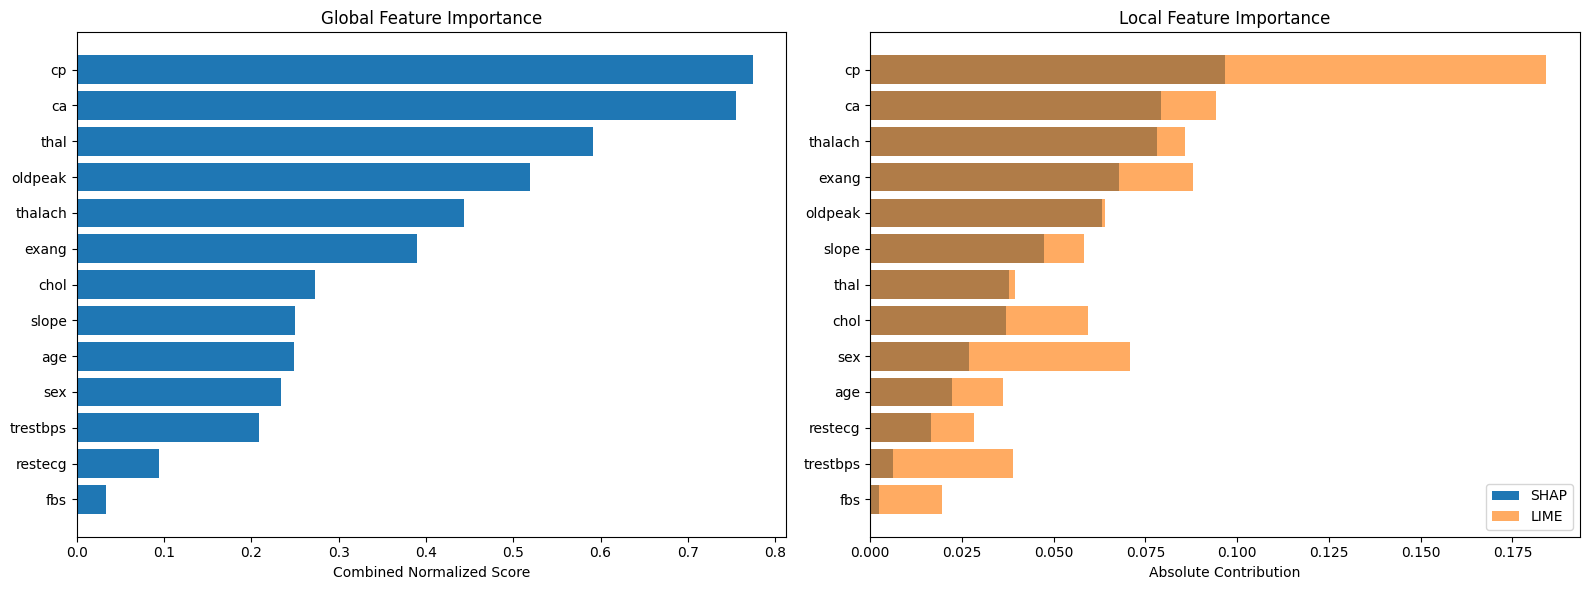

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

global_plot = global_comparison.sort_values(
    "Manual Combined Score",
    ascending=True
)

axes[0].barh(
    global_plot["Feature"],
    global_plot["Manual Combined Score"]
)
axes[0].set_title("Global Feature Importance")
axes[0].set_xlabel("Combined Normalized Score")

local_plot = local_comparison.sort_values(
    "Local SHAP Importance",
    ascending=True
)

axes[1].barh(
    local_plot["Feature"],
    local_plot["Local SHAP Importance"],
    label="SHAP"
)

axes[1].barh(
    local_plot["Feature"],
    local_plot["Local LIME Importance"],
    alpha=0.65,
    label="LIME"
)

axes[1].set_title("Local Feature Importance")
axes[1].set_xlabel("Absolute Contribution")
axes[1].legend()

plt.tight_layout()
plt.show()

In [12]:
top_k = 5

rf_top = set(
    rf_importance.nlargest(top_k, "RF Importance")["Feature"]
)

permutation_top = set(
    permutation_df.nlargest(
        top_k, "Permutation Importance"
    )["Feature"]
)

shap_top = set(
    shap_global_df.nlargest(
        top_k, "Mean Absolute SHAP"
    )["Feature"]
)

selection_votes = pd.DataFrame({
    "Feature": feature_names,
    "RF Top 5": [
        f in rf_top for f in feature_names
    ],
    "Permutation Top 5": [
        f in permutation_top for f in feature_names
    ],
    "SHAP Top 5": [
        f in shap_top for f in feature_names
    ]
})

selection_votes["Method Votes"] = (
    selection_votes[
        ["RF Top 5", "Permutation Top 5", "SHAP Top 5"]
    ].sum(axis=1)
)

selected_features = selection_votes.loc[
    selection_votes["Method Votes"] >= 2,
    "Feature"
].tolist()

if len(selected_features) < 2:
    selected_features = global_comparison.head(5)["Feature"].tolist()

display(
    selection_votes.sort_values(
        "Method Votes", ascending=False
    )
)

print("Selected Features:", selected_features)

,Feature,RF Top 5,Permutation Top 5,SHAP Top 5,Method Votes
2,cp,True,True,True,3
9,oldpeak,True,True,True,3
11,ca,True,True,True,3
7,thalach,True,False,True,2
12,thal,True,False,True,2
1,sex,False,True,False,1
8,exang,False,True,False,1
0,age,False,False,False,0
3,trestbps,False,False,False,0
4,chol,False,False,False,0


Selected Features: ['cp', 'thalach', 'oldpeak', 'ca', 'thal']


In [13]:
reduced_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

reduced_model.fit(
    X_train[selected_features],
    y_train
)

reduced_predictions = reduced_model.predict(
    X_test[selected_features]
)

reduced_accuracy = accuracy_score(
    y_test,
    reduced_predictions
)

accuracy_comparison = pd.DataFrame({
    "Model": ["All Features", "Selected Features"],
    "Number of Features": [
        len(feature_names),
        len(selected_features)
    ],
    "Test Accuracy": [
        accuracy,
        reduced_accuracy
    ]
})

display(accuracy_comparison.round(4))

,Model,Number of Features,Test Accuracy
0,All Features,13,0.8197
1,Selected Features,5,0.8033


In [14]:
global_top5 = global_comparison.head(5)["Feature"].tolist()
local_shap_top5 = local_comparison.nlargest(
    5, "Local SHAP Importance"
)["Feature"].tolist()
local_lime_top5 = local_comparison.nlargest(
    5, "Local LIME Importance"
)["Feature"].tolist()

print("FEATURE IMPORTANCE ANALYSIS REPORT")
print("=" * 45)

print("\n1. OBJECTIVE")
print(
    "To rank feature contributions using Random Forest, "
    "Permutation Importance, SHAP, and LIME, and compare "
    "global and local explanations."
)

print("\n2. DATASET")
print(f"Total observations: {len(df)}")
print(f"Total input features: {len(feature_names)}")
print(f"Training observations: {len(X_train)}")
print(f"Testing observations: {len(X_test)}")

print("\n3. MODEL PERFORMANCE")
print(f"Full model accuracy: {accuracy:.4f}")
print(f"Reduced model accuracy: {reduced_accuracy:.4f}")

print("\n4. TOP GLOBAL FEATURES")
for rank, feature in enumerate(global_top5, start=1):
    print(f"{rank}. {feature}")

print("\n5. TOP LOCAL SHAP FEATURES")
for rank, feature in enumerate(local_shap_top5, start=1):
    print(f"{rank}. {feature}")

print("\n6. TOP LOCAL LIME FEATURES")
for rank, feature in enumerate(local_lime_top5, start=1):
    print(f"{rank}. {feature}")

print("\n7. SELECTED FEATURES")
print(", ".join(selected_features))

print("\n8. FEATURE SELECTION JUSTIFICATION")
print(
    "Features were selected when at least two of three global "
    "methods ranked them in their top five. This consensus rule "
    "reduces reliance on a single importance technique."
)

print("\n9. LIMITATIONS")
print(
    "Importance rankings describe model behaviour, not causal "
    "relationships. Correlated features can share importance. "
    "LIME explains a local neighbourhood and can vary with sampling. "
    "Results depend on the dataset, model, encoding, and test split."
)

print("\n10. CONCLUSION")
print(
    "Global methods summarize overall model reliance, while local "
    "SHAP and LIME explanations describe one selected observation. "
    "The reduced model's test accuracy should be considered before "
    "accepting the selected feature set. Further validation is "
    "needed before making strong claims about feature stability."
)

FEATURE IMPORTANCE ANALYSIS REPORT

1. OBJECTIVE
To rank feature contributions using Random Forest, Permutation Importance, SHAP, and LIME, and compare global and local explanations.

2. DATASET
Total observations: 303
Total input features: 13
Training observations: 242
Testing observations: 61

3. MODEL PERFORMANCE
Full model accuracy: 0.8197
Reduced model accuracy: 0.8033

4. TOP GLOBAL FEATURES
1. cp
2. ca
3. thal
4. oldpeak
5. thalach

5. TOP LOCAL SHAP FEATURES
1. cp
2. ca
3. thalach
4. exang
5. oldpeak

6. TOP LOCAL LIME FEATURES
1. cp
2. ca
3. exang
4. thalach
5. sex

7. SELECTED FEATURES
cp, thalach, oldpeak, ca, thal

8. FEATURE SELECTION JUSTIFICATION
Features were selected when at least two of three global methods ranked them in their top five. This consensus rule reduces reliance on a single importance technique.

9. LIMITATIONS
Importance rankings describe model behaviour, not causal relationships. Correlated features can share importance. LIME explains a local neighbourho